# 04 — V2 Prediction Diagnostics (No Ground Truth Tuning)

**Scope:** inspect the structure and robustness of v2 predictions without evaluating against the provided public five-minute ground truth. All data remain local. This notebook does not annotate frames, choose parameters using ground truth, or create private tracking/video exports.

Prerequisite: run from the project root with `python run_pipeline.py --config config/v2.yaml --output outputs/baseline_v2.csv` (or set `CSV_PATH` below).

In [2]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'games.py').exists():
    ROOT = Path.cwd().parent
assert (ROOT / 'games.py').exists(), 'Open notebook inside project/notebooks or from project root'
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.submission import validate_submission_file, segments_for_labels
import games
CSV_PATH = ROOT/'evaluation'/'results'/'baseline_v2.csv'
print('Project:', ROOT)
print('Prediction file exists:', CSV_PATH.exists())

Project: c:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg
Prediction file exists: True


## 1 — Submission integrity

If the CSV is not available yet, execute the one-command pipeline locally. Successful schema validation **does not prove label accuracy**.

In [3]:
if not CSV_PATH.exists():
    print('Run: python run_pipeline.py --config config/v2.yaml --output outputs/baseline_v2.csv')
else:
    validate_submission_file(CSV_PATH, games.source_frames())
    pred = pd.read_csv(CSV_PATH)
    print('CSV passed strict local checks:', len(pred), 'frames')
    display(pred.head(3))

CSV passed strict local checks: 199319 frames


,frame,label
0,0,X
1,1,X
2,2,X


## 2 — Analysis window

Only the two published graded halves are analyzed. Frames before kickoff, halftime, and after the whistle are not scored.

In [4]:
n=games.source_frames()
half=np.zeros(n,dtype=np.int8)
for h,first,last in games.half_video_blocks(games.GAME):
    half[first:last+1]=h
print('Graded frames:',int((half!=0).sum()))
if CSV_PATH.exists():
    labs=pred.label.to_numpy()
    seg=segments_for_labels(labs,half, fps=games.GAMES[games.GAME]['fps'])
    print('State frame counts (descriptive predictions, NOT ground truth):')
    display(pred.loc[half!=0,'label'].value_counts().to_frame('frames'))

Graded frames: 158857
State frame counts (descriptive predictions, NOT ground truth):


,frames
label,
H,96210
A,59713
D,2934


## 3 — Possession and dead-ball segment lengths

Check fragmentation or unnatural dead-ball patterns. **Do not** optimize to a guessed true possession count.

,segments,median_s,mean_s,p90_s
label,,,,
A,535,1.72,4.465,10.656
D,1,117.36,117.360,117.360
H,535,2.56,7.193,18.936


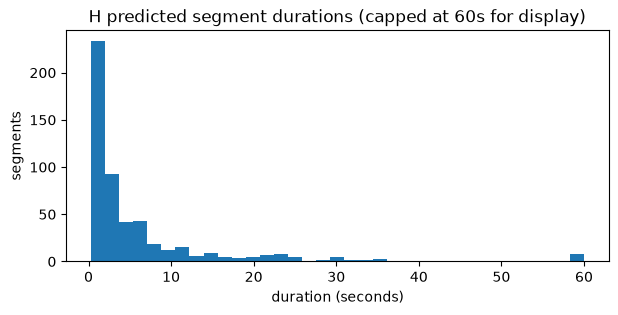

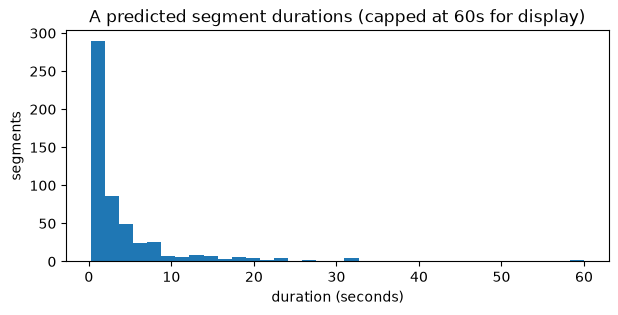

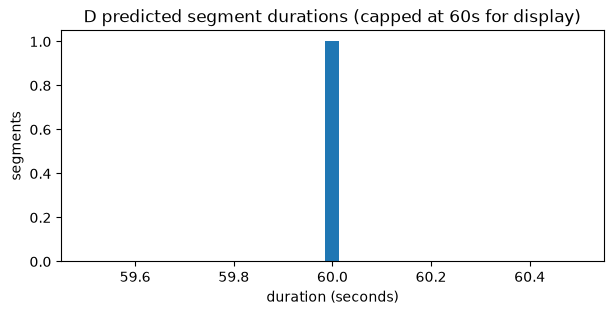

In [5]:
if CSV_PATH.exists():
    display(seg.groupby('label').agg(segments=('n_frames','size'),
              median_s=('duration_s','median'),mean_s=('duration_s','mean'),
              p90_s=('duration_s',lambda x:x.quantile(.9))).round(3))
    for state in ['H','A','D']:
        vals=seg.loc[seg.label==state,'duration_s']
        if len(vals):
            plt.figure(figsize=(7,3))
            plt.hist(vals.clip(upper=60),bins=35)
            plt.title(f'{state} predicted segment durations (capped at 60s for display)')
            plt.xlabel('duration (seconds)');plt.ylabel('segments');plt.show()

## 4 — Transition types

Summarize `H→A`, `A→H`, `H/A→D`, and `D→H/A` to diagnose state machine behavior.

In [6]:
if CSV_PATH.exists():
    transitions=[]
    for h in (1,2):
        ix=np.flatnonzero(half==h)
        for t in ix[1:]:
            if labs[t]!=labs[t-1]:transitions.append((h,labs[t-1]+'→'+labs[t]))
    tdf=pd.DataFrame(transitions,columns=['half','transition'])
    display(pd.crosstab(tdf.transition,tdf.half) if len(tdf) else 'No transitions')

half,1,2
transition,,
A→H,270,264
D→H,0,1
H→A,269,265


## 5 — Synthetic robustness check

This next example creates **invented** observations and makes sure a single false opponent touch does not cause a switch, while a strong short turnover can survive. No supplied match labels are used.

In [7]:
from src.temporal_decoder import decode_states
T=100
hs=np.ones(T)*2;aa=np.zeros(T)
aa[30]=2.3  # weak one-frame flash
sc=np.column_stack([hs,aa,np.zeros(T)])
labs_s=decode_states(sc,np.ones(T,int),config={'ha_cost':1.2,'hd_cost':1.2,'dh_cost':1.2}).labels
print('Weak one-frame opponent evidence switched?',bool(np.any(labs_s=='A')))
sc[50:53,0]=0;sc[50:53,1]=10
labs_s=decode_states(sc,np.ones(T,int),config={'ha_cost':1.2,'hd_cost':1.2,'dh_cost':1.2}).labels
print('Strong brief opponent control retained?',bool(np.all(labs_s[50:53]=='A')))

Weak one-frame opponent evidence switched? False
Strong brief opponent control retained? True


## 6 — Optional local feature analysis (no frame exports)

This step reloads the restricted bundle **only if you explicitly set `RUN_PRIVATE_FEATURE_AUDIT=True`**. It prints aggregate reliability summaries. Do not publish frame-level features, crops, plots containing precise tracking, or raw game assets.

In [9]:
RUN_PRIVATE_FEATURE_AUDIT=True
if RUN_PRIVATE_FEATURE_AUDIT:
    from src.features import build_features
    from src.observation_quality import analyze_observations
    bundle=build_features()
    q=analyze_observations(bundle.frames)
    print('Ball missing share (graded):',float(1-bundle.frames.loc[bundle.frames.graded,'ball_ok'].mean()))
    print('Suspected jumps:',int(q.frames.suspected_ball_jump.sum()))
    print('Valid player motion share:',float(q.frames.motion_reliable.mean()))
    del bundle,q

Ball missing share (graded): 0.40692572565263097
Suspected jumps: 150
Valid player motion share: 0.7675485026515284


## 7 — Review checklist

- [ ] No `X` inside scored halves; no `H/A/D` outside them.
- [ ] The 2,934 published pre-second-kickoff frames are `D`.
- [ ] Inspect aggregate spell distribution; compare to other versions as a **diagnostic only**, not a claimed F1 improvement.
- [ ] Check `outputs/baseline_v2.diagnostics.json` and official `validate_submission.py` result.
- [ ] If a model change is motivated by this notebook, record the hypothesis, synthetic test or independently labeled **other match** supporting it.
- [ ] Never use the provided five-minute GT for tuning or perform manual frame-specific corrections.

**Next:** use legitimate external validation before asserting v2 is better than v1. The official private full-match score is unknown.